In [1]:
import sys
sys.path.insert(0, "../data_prep")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import jump_analysis as ja
from config import DATA_PATH
print("imported ok")

imported ok


In [3]:
wavs = sorted(set(Path(DATA_PATH).glob("train/**/*.WAV")) | set(Path(DATA_PATH).glob("test/**/*.WAV")))
print(DATA_PATH)
print(len(wavs), "WAV files")

/Users/ziyaahmad/Code/mouse_vocalization_2026/data
22516 WAV files


In [4]:
out = Path("jump_review"); out.mkdir(exist_ok=True)
rng = np.random.default_rng(0)
sample = rng.choice(len(wavs), size=5, replace=False)

all_rows = []
for i in sample:
    rows, audit = ja.inspect_file(wavs[i], 10, 2, out)   # threshold kHz, min frames, output folder
    print(wavs[i].name, audit["status"], "active frames:", audit["active_frames"], "jumps:", audit["candidate_jumps"])
    all_rows += rows

pd.DataFrame(all_rows)

DBA_3247_55.WAV included active frames: 87 jumps: 0
DBA_3243_713.WAV included active frames: 39 jumps: 1
DBA_3171_1152.WAV included active frames: 113 jumps: 2
DBA_3171_399.WAV included active frames: 55 jumps: 1
DBA_9858_517.WAV included active frames: 72 jumps: 1


,file,frame,time_ms,pre_khz,post_khz,signed_jump_khz,jump_khz,review_status
0,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,32,17.066667,53.437500,64.570312,11.132812,11.132812,unreviewed
1,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,21,11.200000,67.968750,88.476562,20.507812,20.507812,unreviewed
2,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,39,20.800000,86.132812,64.101562,-22.031250,22.031250,unreviewed
3,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,21,11.200000,85.078125,64.218750,-20.859375,20.859375,unreviewed
4,/Users/ziyaahmad/Code/mouse_vocalization_2026/...,64,34.133333,47.343750,65.273438,17.929688,17.929688,unreviewed


In [5]:
rng = np.random.default_rng(1)
order = rng.permutation(len(wavs))
rows_all, audits = [], []
n_inc = 0
for idx in order:
    if n_inc >= 100:
        break
    p = wavs[int(idx)]
    try:
        rows, audit = ja.inspect_file(p, 10, 2, out)
    except Exception as e:
        audits.append(dict(file=str(p), status="error"))
        continue
    audits.append(audit)
    if audit["status"] == "included":
        n_inc += 1
        rows_all += rows

jumps = pd.DataFrame(rows_all)
print(n_inc, "files,", len(jumps), "jumps,", jumps["file"].nunique(), "files with jumps")

100 files, 81 jumps, 41 files with jumps


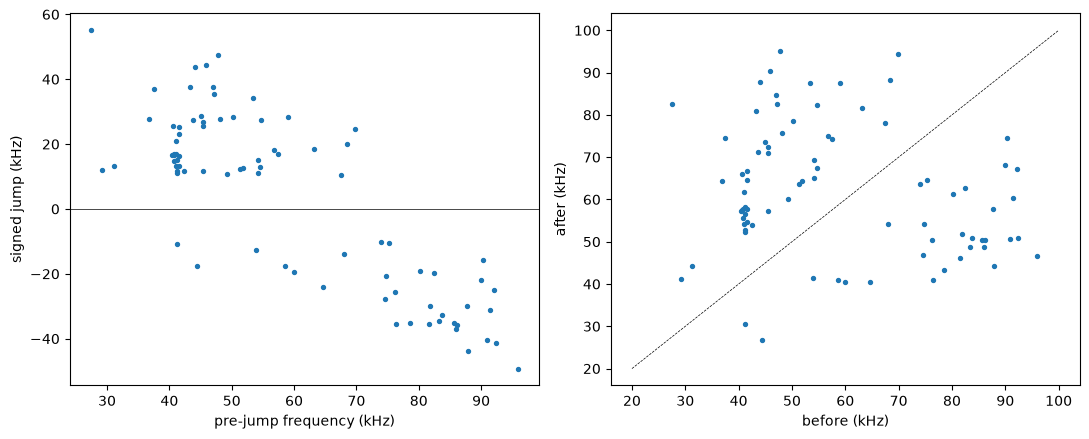

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(jumps["pre_khz"], jumps["signed_jump_khz"], s=8)
ax[0].axhline(0, color="k", lw=0.5)
ax[0].set_xlabel("pre-jump frequency (kHz)"); ax[0].set_ylabel("signed jump (kHz)")
ax[1].scatter(jumps["pre_khz"], jumps["post_khz"], s=8)
ax[1].plot([20, 100], [20, 100], "k--", lw=0.5)
ax[1].set_xlabel("before (kHz)"); ax[1].set_ylabel("after (kHz)")
plt.tight_layout(); plt.show()

In [7]:
cl = jumps[jumps["pre_khz"].between(39, 43)]
print(len(cl), "jumps start near 41 kHz")
print(cl["time_ms"].describe())
print(cl["file"].map(lambda p: Path(p).name).value_counts().head(8))

17 jumps start near 41 kHz
count    17.000000
mean     12.737255
std      13.369128
min       4.266667
25%       6.400000
50%       8.000000
75%      11.733333
max      60.800000
Name: time_ms, dtype: float64
file
DBA_3243_291.WAV     2
DBA_3170_841.WAV     1
DBA_3170_283.WAV     1
DBA_3249_446.WAV     1
DBA_3243_53.WAV      1
DBA_3172_1184.WAV    1
DBA_3170_114.WAV     1
DBA_3248_535.WAV     1
Name: count, dtype: int64


In [8]:
def call_span(path):
    times, freqs, mag, ridge, active = ja.extract_raw_ridge(Path(path))
    idx = np.flatnonzero(np.isfinite(ridge) & active)
    return times[idx[0]] * 1000, times[idx[-1]] * 1000

spans = {p: call_span(p) for p in jumps["file"].unique()}
jumps["from_start"] = jumps["time_ms"] - jumps["file"].map(lambda p: spans[p][0])
jumps["to_end"] = jumps["file"].map(lambda p: spans[p][1]) - jumps["time_ms"]
print(jumps[["from_start", "to_end"]].describe())

clean = jumps[(jumps["from_start"] > 3) & (jumps["to_end"] > 3)]
print(len(jumps), "->", len(clean), "jumps after trimming 3 ms at each end")

       from_start      to_end
count   81.000000   81.000000
mean    26.232099   42.574486
std     24.472695   34.586553
min      1.066667    0.533333
25%      3.733333   12.800000
50%     21.866667   36.266667
75%     46.400000   60.800000
max     83.200000  161.600000
81 -> 59 jumps after trimming 3 ms at each end


59 jumps at 3 ms, 45 jumps at 5 ms


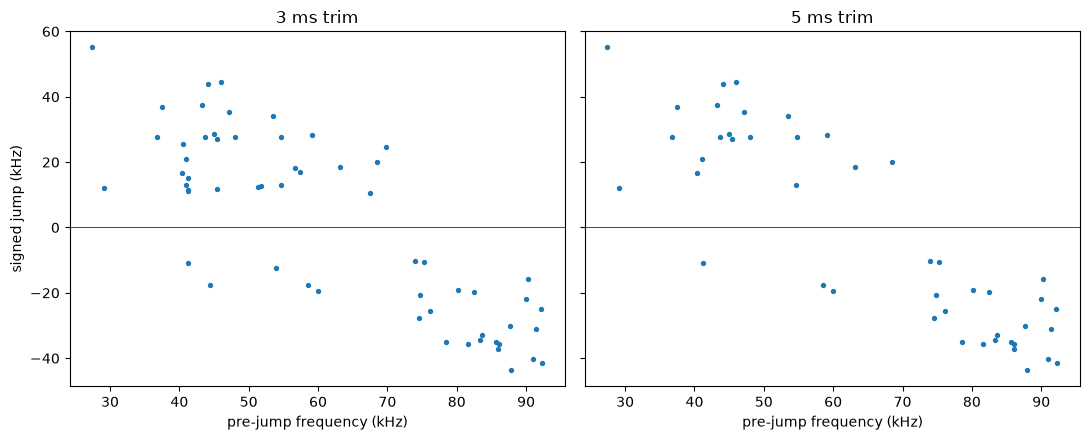

In [9]:
clean5 = jumps[(jumps["from_start"] > 5) & (jumps["to_end"] > 5)]
print(len(clean), "jumps at 3 ms,", len(clean5), "jumps at 5 ms")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for a, data, name in [(ax[0], clean, "3 ms trim"), (ax[1], clean5, "5 ms trim")]:
    a.scatter(data["pre_khz"], data["signed_jump_khz"], s=8)
    a.axhline(0, color="k", lw=0.5)
    a.set_title(name); a.set_xlabel("pre-jump frequency (kHz)")
ax[0].set_ylabel("signed jump (kHz)")
plt.tight_layout(); plt.show()

In [10]:
c = clean5.copy()
c["ratio"] = c["post_khz"] / c["pre_khz"]
for name, g in c.groupby(c["signed_jump_khz"] > 0):
    print("up" if name else "down", len(g), "jumps")
    print(" landing (kHz): median %.1f, spread (std) %.1f" % (g["post_khz"].median(), g["post_khz"].std()))
    print(" ratio post/pre: median %.2f, spread (std) %.2f" % (g["ratio"].median(), g["ratio"].std()))

down 25 jumps
 landing (kHz): median 50.6, spread (std) 10.3
 ratio post/pre: median 0.66, spread (std) 0.10
up 20 jumps
 landing (kHz): median 78.3, spread (std) 12.5
 ratio post/pre: median 1.61, spread (std) 0.39


In [11]:
out400 = Path("jump_review400"); out400.mkdir(exist_ok=True)
rng = np.random.default_rng(2)
order = rng.permutation(len(wavs))
rows400, n_inc = [], 0
for idx in order:
    if n_inc >= 400:
        break
    p = wavs[int(idx)]
    try:
        rows, audit = ja.inspect_file(p, 10, 2, out400)
    except Exception:
        continue
    if audit["status"] == "included":
        n_inc += 1
        rows400 += rows

jumps400 = pd.DataFrame(rows400)
jumps400.to_csv("jumps400.csv", index=False)
print(n_inc, "files,", len(jumps400), "jumps,", jumps400["file"].nunique(), "files with jumps")

400 files, 299 jumps, 143 files with jumps


In [12]:
odd = jumps[(jumps["pre_khz"] < 65) & (jumps["signed_jump_khz"] < 0)]
print(odd[["file", "pre_khz", "post_khz", "time_ms"]])

                                                 file    pre_khz   post_khz  \
0   /Users/ziyaahmad/Code/mouse_vocalization_2026/...  53.906250  41.367188   
7   /Users/ziyaahmad/Code/mouse_vocalization_2026/...  44.414062  26.718750   
8   /Users/ziyaahmad/Code/mouse_vocalization_2026/...  58.593750  40.898438   
15  /Users/ziyaahmad/Code/mouse_vocalization_2026/...  41.250000  30.468750   
69  /Users/ziyaahmad/Code/mouse_vocalization_2026/...  64.687500  40.546875   
71  /Users/ziyaahmad/Code/mouse_vocalization_2026/...  60.000000  40.429688   

      time_ms  
0    5.866667  
7   24.533333  
8   17.600000  
15  23.466667  
69   9.600000  
71  59.733333  


In [13]:
print(odd["file"].map(lambda p: Path(p).name).tolist())

['DBA_3170_841.WAV', 'DBA_3248_672.WAV', 'DBA_3243_53.WAV', 'DBA_3248_535.WAV', 'DBA_3243_291.WAV', 'DBA_3243_291.WAV']


In [14]:
spans = {p: call_span(p) for p in jumps400["file"].unique()}
jumps400["from_start"] = jumps400["time_ms"] - jumps400["file"].map(lambda p: spans[p][0])
jumps400["to_end"] = jumps400["file"].map(lambda p: spans[p][1]) - jumps400["time_ms"]
c400 = jumps400[(jumps400["from_start"] > 5) & (jumps400["to_end"] > 5)]
c400.to_csv("c400.csv", index=False)
print(len(jumps400), "->", len(c400), "jumps after a 5 ms trim")

299 -> 187 jumps after a 5 ms trim


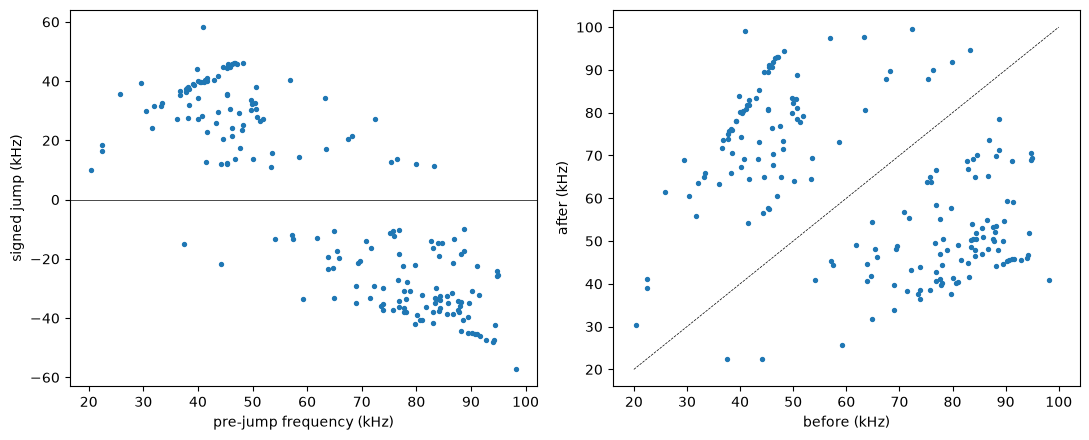

down 100 | landing median 48.0 std 11.1 | ratio median 0.60 std 0.12
up 87 | landing median 77.8 std 13.5 | ratio median 1.75 std 0.31


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(c400["pre_khz"], c400["signed_jump_khz"], s=8)
ax[0].axhline(0, color="k", lw=0.5)
ax[0].set_xlabel("pre-jump frequency (kHz)"); ax[0].set_ylabel("signed jump (kHz)")
ax[1].scatter(c400["pre_khz"], c400["post_khz"], s=8)
ax[1].plot([20, 100], [20, 100], "k--", lw=0.5)
ax[1].set_xlabel("before (kHz)"); ax[1].set_ylabel("after (kHz)")
plt.tight_layout(); plt.show()

c400 = c400.assign(ratio=c400["post_khz"] / c400["pre_khz"])
for name, g in c400.groupby(c400["signed_jump_khz"] > 0):
    print("up" if name else "down", len(g),
          "| landing median %.1f std %.1f" % (g["post_khz"].median(), g["post_khz"].std()),
          "| ratio median %.2f std %.2f" % (g["ratio"].median(), g["ratio"].std()))

In [16]:
up = c400[c400["signed_jump_khz"] > 0]
print("upward jumps:", len(up))
print("landing above 95 kHz:", (up["post_khz"] > 95).sum())
print("starts above 55 kHz (1.7x would exceed 93 kHz):", (up["pre_khz"] > 55).sum())
print("all jumps starting above 55 kHz, up vs down:",
      (c400[c400["pre_khz"] > 55]["signed_jump_khz"] > 0).sum(), "up,",
      (c400[c400["pre_khz"] > 55]["signed_jump_khz"] < 0).sum(), "down")

upward jumps: 87
landing above 95 kHz: 4
starts above 55 kHz (1.7x would exceed 93 kHz): 11
all jumps starting above 55 kHz, up vs down: 11 up, 97 down


In [17]:
for name, g in c400.groupby(c400["signed_jump_khz"] > 0):
    s, b = np.polyfit(np.log(g["pre_khz"]), np.log(g["post_khz"]), 1)
    print("up" if name else "down", len(g), "slope of log(post) vs log(pre): %.2f" % s)

down 100 slope of log(post) vs log(pre): 0.86
up 87 slope of log(post) vs log(pre): 0.55


In [18]:
w = 5   # frames before and after
res = []
for p, g in c400.groupby("file"):
    times, freqs, mag, ridge, active = ja.extract_raw_ridge(Path(p))
    for _, r in g.iterrows():
        j = int(r["frame"])
        if j - w < 0 or j + w > len(ridge): continue
        pre, post = np.log(ridge[j-w:j]), np.log(ridge[j:j+w])
        if not (np.isfinite(pre).all() and np.isfinite(post).all()): continue
        t = times[j-w:j+w] * 1000
        res.append(dict(file=p, time_ms=r["time_ms"], up=r["signed_jump_khz"] > 0,
                        slope_pre=np.polyfit(t[:w], pre, 1)[0],
                        slope_post=np.polyfit(t[w:], post, 1)[0]))
R = pd.DataFrame(res)
print(len(R), "jumps; corr(pre slope, post slope) = %.2f" % R["slope_pre"].corr(R["slope_post"]))

R = R.sort_values(["file", "time_ms"])
R["gap_ms"] = R.groupby("file")["time_ms"].diff()
R["flip"] = R.groupby("file")["up"].transform(lambda s: s != s.shift())
multi = R.dropna(subset=["gap_ms"])
print("jumps that follow another jump in the same call:", len(multi))
print("time since previous jump (ms):", multi["gap_ms"].describe()[["25%", "50%", "75%"]].round(1).tolist())
print("fraction going the opposite direction:", multi["flip"].mean())

175 jumps; corr(pre slope, post slope) = 0.14
jumps that follow another jump in the same call: 105
time since previous jump (ms): [2.1, 4.8, 17.6]
fraction going the opposite direction: 0.9428571428571428


In [19]:
cc = c400.sort_values(["file", "time_ms"]).copy()
nxt = cc.groupby("file").shift(-1)
m = nxt["post_khz"].notna() & (np.sign(nxt["signed_jump_khz"]) != np.sign(cc["signed_jump_khz"]))
ret = nxt["post_khz"][m] / cc["pre_khz"][m]
gap = nxt["time_ms"][m] - cc["time_ms"][m]
print(len(ret), "hop and return pairs")
print("return ratio (landing after 2nd jump / start before 1st jump), 25/50/75%:",
      ret.quantile([0.25, 0.5, 0.75]).round(2).tolist())
print("same, only pairs under 20 ms apart:",
      ret[gap < 20].quantile([0.25, 0.5, 0.75]).round(2).tolist(), "n =", (gap < 20).sum())

103 hop and return pairs
return ratio (landing after 2nd jump / start before 1st jump), 25/50/75%: [0.94, 0.99, 1.03]
same, only pairs under 20 ms apart: [0.96, 1.0, 1.05] n = 82


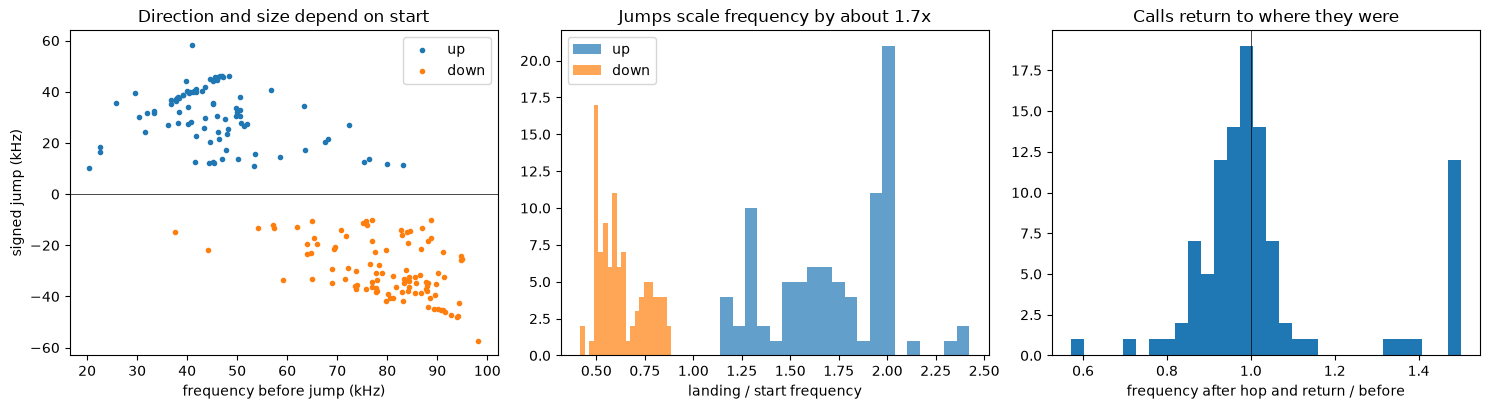

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
up = c400["signed_jump_khz"] > 0
ax[0].scatter(c400["pre_khz"][up], c400["signed_jump_khz"][up], s=9, label="up")
ax[0].scatter(c400["pre_khz"][~up], c400["signed_jump_khz"][~up], s=9, label="down")
ax[0].axhline(0, color="k", lw=0.5); ax[0].legend()
ax[0].set_xlabel("frequency before jump (kHz)"); ax[0].set_ylabel("signed jump (kHz)")
ax[0].set_title("Direction and size depend on start")
ax[1].hist(c400["ratio"][up], bins=20, alpha=0.7, label="up")
ax[1].hist(c400["ratio"][~up], bins=20, alpha=0.7, label="down")
ax[1].set_xlabel("landing / start frequency"); ax[1].legend()
ax[1].set_title("Jumps scale frequency by about 1.7x")
ax[2].hist(ret.clip(0.5, 1.5), bins=30)
ax[2].axvline(1, color="k", lw=0.5)
ax[2].set_xlabel("frequency after hop and return / before")
ax[2].set_title("Calls return to where they were")
plt.tight_layout(); plt.savefig("jump_summary.png", dpi=150); plt.show()

In [21]:
r = c400["ratio"]
octv = ((r / 2 - 1).abs() < 0.05) | ((r / 0.5 - 1).abs() < 0.05)
print(octv.sum(), "of", len(c400), "jumps are within 5% of an octave (2.0 or 0.5)")
names = c400[octv]["file"].map(lambda p: Path(p).parent.name + "_" + Path(p).stem + "_review.png")
print(names.head(8).tolist())

54 of 187 jumps are within 5% of an octave (2.0 or 0.5)
['train_DBA_3171_1602_review.png', 'train_DBA_3249_562_review.png', 'train_DBA_3249_562_review.png', 'train_DBA_3249_905_review.png', 'train_DBA_3249_905_review.png', 'train_DBA_3247_673_review.png', 'train_DBA_3247_972_review.png', 'train_DBA_3247_972_review.png']


In [22]:
order = np.random.default_rng(2).permutation(len(wavs))   # same 400 files as before
cache, n_inc = {}, 0
for idx in order:
    if n_inc >= 400:
        break
    p = wavs[int(idx)]
    try:
        times, freqs, mag, ridge, active = ja.extract_raw_ridge(p)
    except Exception:
        continue
    if (np.isfinite(ridge) & active).sum() < 10:
        continue
    n_inc += 1
    amp = np.full(len(ridge), np.nan)
    t_ok = np.flatnonzero(np.isfinite(ridge))
    k = np.abs(freqs[None, :] - ridge[t_ok][:, None]).argmin(axis=1)
    amp[t_ok] = 20 * np.log10(mag[k, t_ok] + 1e-12)
    cache[str(p)] = dict(ridge=ridge / 1000, amp=amp, active=active)
print(len(cache), "files cached")

400 files cached


In [23]:
c = c400.sort_values(["file", "time_ms"]).copy()
c["ratio"] = c["post_khz"] / c["pre_khz"]
c["octave"] = ((c["ratio"] / 2 - 1).abs() < 0.05) | ((c["ratio"] / 0.5 - 1).abs() < 0.05)
c["up"] = c["signed_jump_khz"] > 0
c["dwell_ms"] = c.groupby("file")["time_ms"].shift(-1) - c["time_ms"]
c["state"] = np.where(c["up"], "upper", "lower")   # mode the call is in after this jump
print(c.groupby("state")["dwell_ms"].describe()[["count", "25%", "50%", "75%"]].round(1))
first = c.groupby("file").head(1)
print(pd.Series(np.where(first["up"], "began in lower mode", "began in upper mode")).value_counts())

       count  25%  50%   75%
state                       
lower   74.0  1.7  8.8  28.9
upper   38.0  2.1  2.7   7.7
began in upper mode    57
began in lower mode    18
Name: count, dtype: int64


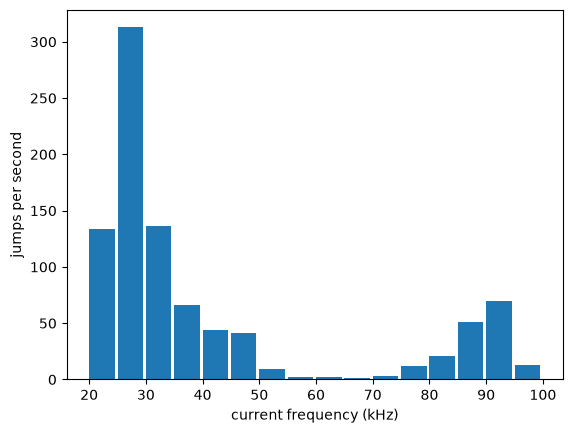

 bin  frames  jumps  per_s
  20    42.0      3  134.0
  25    12.0      2  312.7
  30    69.0      5  136.0
  35   425.0     15   66.2
  40   850.0     20   44.1
  45  1095.0     24   41.1
  50  2082.0     10    9.0
  55  4695.0      5    2.0
  60  7603.0      8    2.0
  65  8889.0      8    1.7
  70  6329.0      9    2.7
  75  3412.0     22   12.1
  80  1877.0     21   21.0
  85   730.0     20   51.4
  90   378.0     14   69.5
  95   143.0      1   13.1


In [24]:
bins = np.arange(20, 105, 5)
frames = np.zeros(len(bins) - 1)
for v in cache.values():
    r = v["ridge"][np.isfinite(v["ridge"]) & v["active"]]
    frames += np.histogram(r, bins=bins)[0]
njump = np.histogram(c["pre_khz"], bins=bins)[0]
rate = njump / np.maximum(frames, 1) / 0.000533     # jumps per second spent at that frequency
plt.bar(bins[:-1], rate, width=4.5, align="edge")
plt.xlabel("current frequency (kHz)"); plt.ylabel("jumps per second"); plt.show()
print(pd.DataFrame(dict(bin=bins[:-1], frames=frames, jumps=njump, per_s=rate.round(1))).to_string(index=False))

In [25]:
dips, chg = [], []
for _, r in c.iterrows():
    a = cache[r["file"]]["amp"]; j = int(r["frame"])
    if j < 5 or j + 5 > len(a):
        dips.append(np.nan); chg.append(np.nan); continue
    before, after = np.nanmedian(a[j-5:j-1]), np.nanmedian(a[j+1:j+5])
    at = np.nanmin(a[j-1:j+1])
    dips.append(at - (before + after) / 2); chg.append(after - before)
c["amp_dip_db"], c["amp_change_db"] = dips, chg
print(c.groupby("octave")[["amp_dip_db", "amp_change_db"]].median().round(2))

        amp_dip_db  amp_change_db
octave                           
False        -3.44           2.18
True         -1.68          -0.24


In [26]:
def rec(p): return Path(p).stem.rsplit("_", 1)[0]
A = pd.DataFrame([dict(rec=rec(p), active_s=(np.isfinite(v["ridge"]) & v["active"]).sum() * 0.000533)
                  for p, v in cache.items()]).groupby("rec").agg(files=("active_s", "size"), active_s=("active_s", "sum"))
A["jumps"] = c.groupby(c["file"].map(rec)).size().reindex(A.index).fillna(0)
A["per_s"] = A["jumps"] / A["active_s"]
B = A[A["files"] >= 5].sort_values("per_s")
print(pd.concat([B.head(8), B.tail(8)]).round(2))

          files  active_s  jumps  per_s
rec                                    
DBA_3070      7      0.44    0.0   0.00
DBA_9859     34      1.63    2.0   1.23
DBA_3248     10      0.60    2.0   3.34
DBA_3243     17      0.84    3.0   3.59
DBA_9857     20      0.78    3.0   3.87
DBA_9856     13      0.77    3.0   3.89
DBA_3240     13      0.69    3.0   4.36
DBA_3246     17      0.64    3.0   4.67
DBA_3074     14      0.67    5.0   7.48
DBA_3171     32      1.65   15.0   9.07
DBA_9858     17      0.58    6.0  10.35
DBA_3249     31      2.46   28.0  11.39
DBA_3241     29      1.48   21.0  14.19
DBA_3247     14      0.76   11.0  14.41
DBA_3172     22      1.38   33.0  23.87
DBA_3245     15      0.70   21.0  29.98


In [27]:
fr = []
for _, r in c.iterrows():
    rg = cache[r["file"]]["ridge"]; j = int(r["frame"])
    fr.append((rg[j] - rg[j-1]) / (r["post_khz"] - r["pre_khz"]) if j >= 1 else np.nan)
c["one_frame_share"] = fr
print("median share of the jump done in one frame (1.0 = instant):", round(np.nanmedian(fr), 2))
print("fraction with over 80% done in one frame:", round(np.nanmean(np.array(fr) > 0.8), 2))

median share of the jump done in one frame (1.0 = instant): 1.0
fraction with over 80% done in one frame: 0.98


          n  frac_up  median_dwell_ms  median_amp_dip_db  \
octave                                                     
False   133     0.41            12.80              -3.44   
True     54     0.59             2.67              -1.68   

        median_one_frame_share  
octave                          
False                      1.0  
True                       1.0  


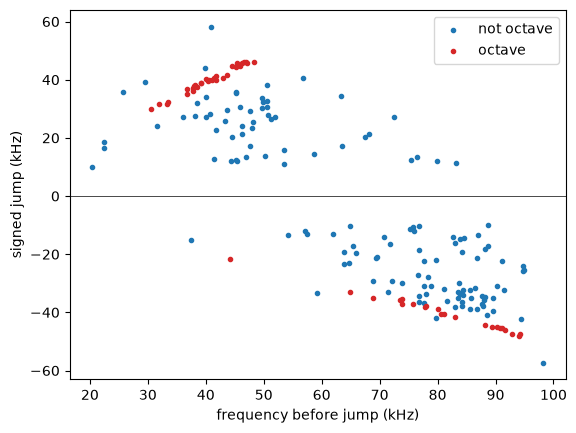

In [28]:
S = c.groupby("octave").agg(n=("up", "size"), frac_up=("up", "mean"),
                            median_dwell_ms=("dwell_ms", "median"),
                            median_amp_dip_db=("amp_dip_db", "median"),
                            median_one_frame_share=("one_frame_share", "median"))
print(S.round(2))
for flag, col in [(False, "tab:blue"), (True, "tab:red")]:
    g = c[c["octave"] == flag]
    plt.scatter(g["pre_khz"], g["signed_jump_khz"], s=9, c=col, label="octave" if flag else "not octave")
plt.axhline(0, color="k", lw=0.5); plt.legend()
plt.xlabel("frequency before jump (kHz)"); plt.ylabel("signed jump (kHz)"); plt.show()